#Delivery Operations Zomato Analytics

In [4]:
import numpy as np
import pandas as pd

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

##Problem Statement

* Waktu pengiriman untuk layanan pengantaran makanan yang dipengaruhi oleh berbagai faktor, seperti jam sibuk dan kondisi cuaca buruk, berdampak pada kepuasan pelanggan dan efisiensi operasional secara keseluruhan.

* Bisnis perlu memahami bagaimana berbagai faktor, seperti peringkat kurir pengantar, kondisi cuaca, and volume pengantaran, memengaruhi waktu pengiriman untuk mengoptimalkan operasional.

##Solution Approach

###Masalah yang Diselesaikan:

* Mengatasi masalah waktu pengiriman yang tidak konsisten selama jam sibuk dan kondisi cuaca buruk yang berdampak negatif terhadap kepuasan pelanggan serta efisiensi operasional secara keseluruhan untuk layanan pengantaran makanan.

###Cara Menyelesaikannya:

1. Menganalisis data waktu pengiriman dengan membuat berbagai grafik guna mengidentifikasi tren dan pola.

2. Melakukan pengujian hipotesis untuk menentukan pengaruh dari faktor-faktor utama, termasuk peringkat kurir pengantar, kondisi cuaca, dan volume pengantaran, terhadap waktu pengiriman.

3. Merumuskan rekomendasi strategis yang bertujuan untuk mengoptimalkan operasional berdasarkan hasil analisis tersebut.

### Dampak yang Diberikan terhadap Bisnis:

1. Meningkatkan pemahaman mengenai faktor-faktor yang memengaruhi waktu pengiriman, sehingga menghasilkan pengambilan keputusan yang lebih baik.

2. Meningkatkan efisiensi operasional melalui penerapan strategi berbasis data, yang menghasilkan waktu pengiriman yang lebih cepat dan kepuasan pelanggan yang lebih tinggi.

3. Memposisikan bisnis agar lebih siap beradaptasi secara efektif terhadap jam sibuk, kondisi cuaca buruk, serta berbagai faktor lainnya, yang pada akhirnya mendorong tingkat retensi pelanggan dan pertumbuhan pendapatan yang lebih tinggi.

##Import Libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

##Read Dataset

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("saurabhbadole/zomato-delivery-operations-analytics-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'zomato-delivery-operations-analytics-dataset' dataset.
Path to dataset files: /kaggle/input/zomato-delivery-operations-analytics-dataset


##Data Description

In [11]:
# Viewing the first few rows of a DataFrame.

import os
import pandas as pd

files = os.listdir(path)
csv_file = [f for f in files if f.endswith('.csv')][0]

df = pd.read_csv(os.path.join(path, csv_file))

df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


In [12]:
# Viewing the last few rows of a DataFrame.
df.tail()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
45579,0x7c09,JAPRES04DEL01,30.0,4.8,26.902328,75.794257,26.912328,75.804257,24-03-2022,11:35,11:45,Windy,High,1,Meal,motorcycle,0.0,No,Metropolitian,32
45580,0xd641,AGRRES16DEL01,21.0,4.6,0.000000,0.000000,0.070000,0.070000,16-02-2022,19:55,20:10,Windy,Jam,0,Buffet,motorcycle,1.0,No,Metropolitian,36
45581,0x4f8d,CHENRES08DEL03,30.0,4.9,13.022394,80.242439,13.052394,80.272439,11-03-2022,23:50,24:05:00,Cloudy,Low,1,Drinks,scooter,0.0,No,Metropolitian,16
45582,0x5eee,COIMBRES11DEL01,20.0,4.7,11.001753,76.986241,11.041753,77.026241,07-03-2022,13:35,13:40,Cloudy,High,0,Snack,motorcycle,1.0,No,Metropolitian,26
45583,0x5fb2,RANCHIRES09DEL02,23.0,4.9,23.351058,85.325731,23.431058,85.405731,02-03-2022,17:10,17:15,Fog,Medium,2,Snack,scooter,1.0,No,Metropolitian,36


In [13]:
# Retrieving the dimensions of a DataFrame (Rows, Columns).

df.shape

(45584, 20)

In [14]:
# Colums names
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
      dtype='object')

In [15]:
# Lowering all the columns so there is no typo while mentioning column names
df.columns = [col.lower() for col in df.columns]

In [16]:
# Rename the column
df.rename(columns = {"time_taken (min)" : "time_taken_min"},inplace = True)

In [17]:
# Information about Data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           45584 non-null  object 
 1   delivery_person_id           45584 non-null  object 
 2   delivery_person_age          43730 non-null  float64
 3   delivery_person_ratings      43676 non-null  float64
 4   restaurant_latitude          45584 non-null  float64
 5   restaurant_longitude         45584 non-null  float64
 6   delivery_location_latitude   45584 non-null  float64
 7   delivery_location_longitude  45584 non-null  float64
 8   order_date                   45584 non-null  object 
 9   time_orderd                  43853 non-null  object 
 10  time_order_picked            45584 non-null  object 
 11  weather_conditions           44968 non-null  object 
 12  road_traffic_density         44983 non-null  object 
 13  vehicle_conditio

In [18]:
# Display the data type of each column in a DataFrame

df.dtypes

,0
id,object
delivery_person_id,object
delivery_person_age,float64
delivery_person_ratings,float64
restaurant_latitude,float64
restaurant_longitude,float64
delivery_location_latitude,float64
delivery_location_longitude,float64
order_date,object
time_orderd,object


In [19]:
# Change data types of columns order_date to datetime
df['order_date'] = pd.to_datetime(df["order_date"],format="%d-%m-%Y")

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   id                           45584 non-null  object        
 1   delivery_person_id           45584 non-null  object        
 2   delivery_person_age          43730 non-null  float64       
 3   delivery_person_ratings      43676 non-null  float64       
 4   restaurant_latitude          45584 non-null  float64       
 5   restaurant_longitude         45584 non-null  float64       
 6   delivery_location_latitude   45584 non-null  float64       
 7   delivery_location_longitude  45584 non-null  float64       
 8   order_date                   45584 non-null  datetime64[ns]
 9   time_orderd                  43853 non-null  object        
 10  time_order_picked            45584 non-null  object        
 11  weather_conditions           44968 non-nu

##Summary Statistics for Categorical Variables

In [21]:
# Retrieving statistics of the numerical columns in a DataFrame.

df.describe(include = "object").T

,count,unique,top,freq
id,45584,45584,0x2bed,1
delivery_person_id,45584,1320,PUNERES01DEL01,67
time_orderd,43853,176,21:55,461
time_order_picked,45584,193,21:30,495
weather_conditions,44968,6,Fog,7653
road_traffic_density,44983,4,Low,15476
type_of_order,45584,4,Snack,11530
type_of_vehicle,45584,4,motorcycle,26429
festival,45356,2,No,44460
city,44384,3,Metropolitian,34087


##Missing Values Treatment

In [22]:
# Checking null values
(df.isnull().sum()/len(df)) * 100

,0
id,0.000000
delivery_person_id,0.000000
delivery_person_age,4.067217
delivery_person_ratings,4.185679
restaurant_latitude,0.000000
restaurant_longitude,0.000000
delivery_location_latitude,0.000000
delivery_location_longitude,0.000000
order_date,0.000000
time_orderd,3.797385


* Terdapat missing values (nilai yang kosong) pada kolom-kolom seperti delivery_person_age, delivery_person_ratings, time_orderd, weather_conditions, road_traffic_density, multiple_deliveries, dan city.

* Karena missing values tersebut mencakup kurang dari 5% dari keseluruhan data, kita akan melanjutkan dengan menghapus (drop) baris-baris yang memiliki nilai kosong tersebut.

In [23]:
# Drop the missing values
df.dropna(inplace = True)

In [24]:
(df.isnull().sum()/len(df)) * 100

,0
id,0.0
delivery_person_id,0.0
delivery_person_age,0.0
delivery_person_ratings,0.0
restaurant_latitude,0.0
restaurant_longitude,0.0
delivery_location_latitude,0.0
delivery_location_longitude,0.0
order_date,0.0
time_orderd,0.0


In [25]:
# Check for Duplicate values
df.duplicated().sum()

np.int64(0)

In [26]:
df.nunique()

,0
id,41359
delivery_person_id,1320
delivery_person_age,20
delivery_person_ratings,26
restaurant_latitude,487
restaurant_longitude,389
delivery_location_latitude,4361
delivery_location_longitude,4361
order_date,44
time_orderd,176


##Creating new features

In [27]:
# Extractin month from the order date column

df['order_month'] = pd.DatetimeIndex(df['order_date']).strftime('%b')

In [28]:
#Creating new feature for age bins for further analysis
age = [20,25,30,35,40]
label = ["20-24","25-29","30-34","35+"]
df["age_bins"] = pd.cut(df["delivery_person_age"],bins = age,labels=label)

In [29]:
# Creating peak hour indicating whether an order was placed during peak hours

df['time_orderd'] = pd.to_datetime(df['time_orderd'], format='%H:%M', errors='coerce')

def is_peak_hour(df):
    hour = pd.to_datetime(df['time_orderd']).hour
    return 1 if (11 <= hour < 14) or (17 <= hour < 21) else 0

df['peak_hours'] = df.apply(is_peak_hour, axis=1)

##Outlier Treatment

Saya akan memeriksa outlier (data pencilan) menggunakan metode IQR (Interquartile Range) untuk fitur-fitur kontinu.

In [30]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
delivery_person_age,41359.0,29.609783,20.0,25.0,30.0,35.0,39.0,5.764045
delivery_person_ratings,41359.0,4.633202,2.5,4.5,4.7,4.9,5.0,0.315887
restaurant_latitude,41359.0,17.25466,-30.902872,12.933298,18.554382,22.732225,30.914057,7.691901
restaurant_longitude,41359.0,70.775773,0.0,73.170283,75.898497,78.045359,88.433452,21.124028
delivery_location_latitude,41359.0,17.472763,0.01,12.989096,18.636947,22.785536,31.054057,7.337562
delivery_location_longitude,41359.0,70.839652,0.01,73.278436,76.002471,78.107079,88.563452,21.12423
order_date,41359,2022-03-13 16:00:34.120747776,2022-02-11 00:00:00,2022-03-04 00:00:00,2022-03-15 00:00:00,2022-03-27 00:00:00,2022-04-06 00:00:00,NaN
time_orderd,37525,1900-01-01 18:07:49.766822144,1900-01-01 08:10:00,1900-01-01 15:55:00,1900-01-01 19:20:00,1900-01-01 21:35:00,1900-01-01 23:55:00,NaN
vehicle_condition,41359.0,0.995914,0.0,0.0,1.0,2.0,2.0,0.81798
multiple_deliveries,41359.0,0.748108,0.0,0.0,1.0,1.0,3.0,0.572974


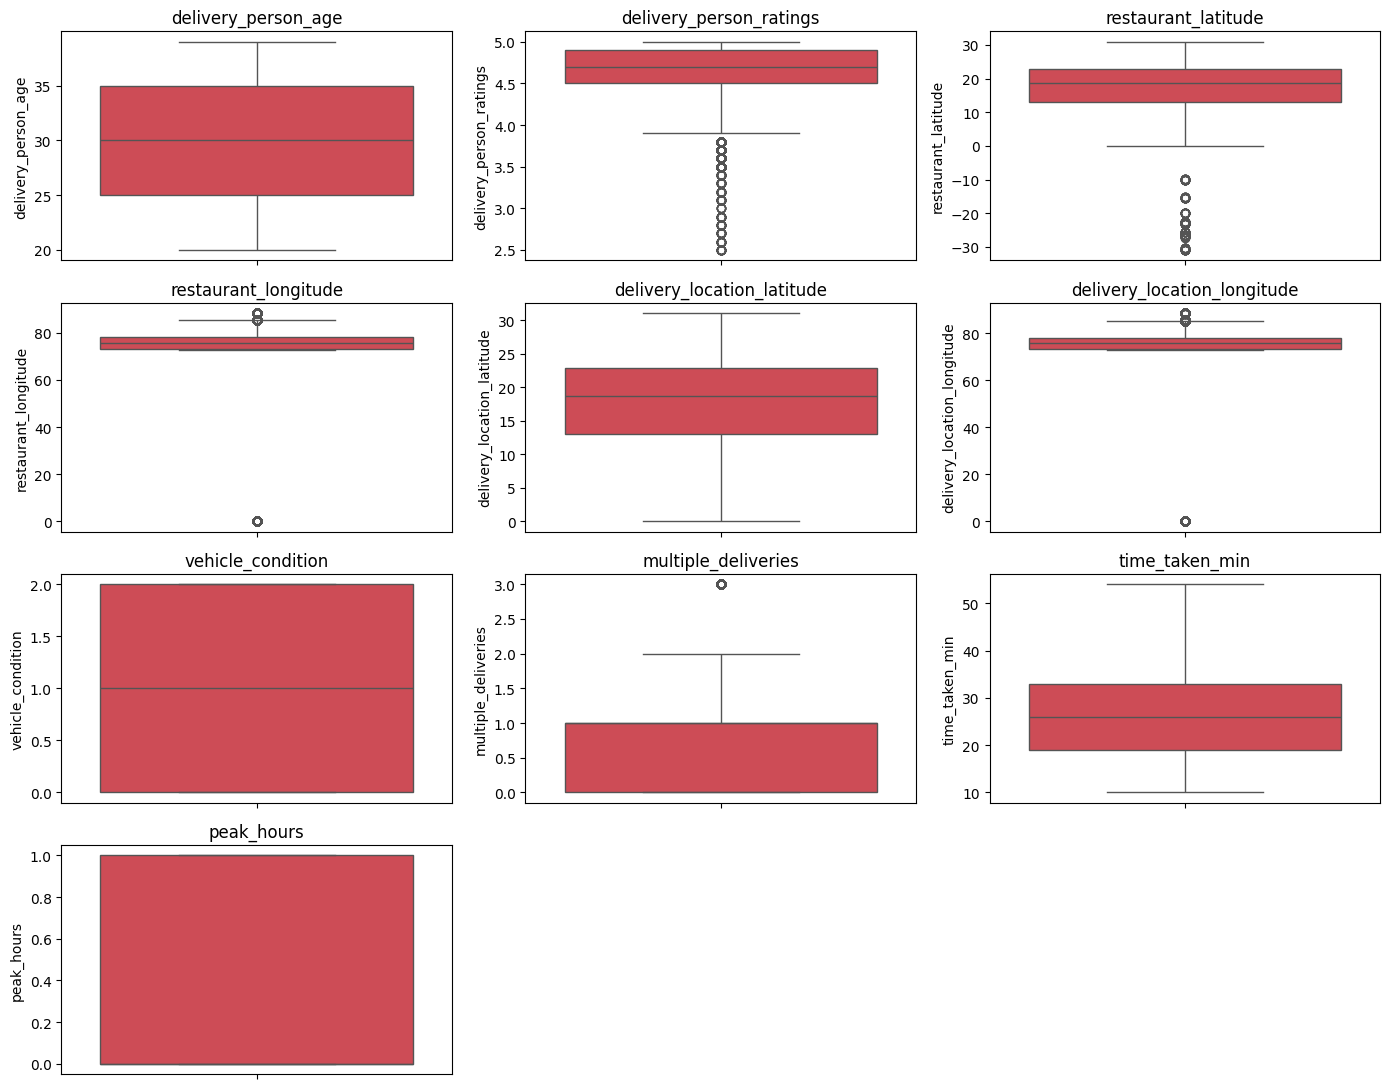

In [31]:
numeric_columns = df.select_dtypes(include=["number"])

plt.figure(figsize=(14,11))
for i,col in enumerate (numeric_columns.columns):
  plt.subplot(4,3,i+1)
  sns.boxplot(df[col],color="#E23744")
  plt.title(col)
plt.tight_layout()
plt.show()

In [33]:
# Select only numerical columns
numeric_columns = df.select_dtypes(include=["number"])

def identify_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return data[(data < lower_bound) | (data > upper_bound)]

outlier_counts = {}  # Dictionary to store outlier counts for each column

for col in numeric_columns.columns:
    outliers = identify_outliers(numeric_columns[col])
    outlier_counts[col] = len(outliers)

# Print the count of outliers for each numerical column
for col, count in outlier_counts.items():
    print(f"Count of outliers present in {col}: {count}")
    print(f"% Count of outliers present in {col}: {count/ len(df)*100}\n")

Count of outliers present in delivery_person_age: 0
% Count of outliers present in delivery_person_age: 0.0

Count of outliers present in delivery_person_ratings: 1099
% Count of outliers present in delivery_person_ratings: 2.657220919267874

Count of outliers present in restaurant_latitude: 146
% Count of outliers present in restaurant_latitude: 0.3530066007398631

Count of outliers present in restaurant_longitude: 4097
% Count of outliers present in restaurant_longitude: 9.905945501583693

Count of outliers present in delivery_location_latitude: 0
% Count of outliers present in delivery_location_latitude: 0.0

Count of outliers present in delivery_location_longitude: 5900
% Count of outliers present in delivery_location_longitude: 14.265335235378032

Count of outliers present in vehicle_condition: 0
% Count of outliers present in vehicle_condition: 0.0

Count of outliers present in multiple_deliveries: 337
% Count of outliers present in multiple_deliveries: 0.8148166058173553

Count 

In [34]:
def remove_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return data[(data >= lower_bound) & (data <= upper_bound)]

# Remove outliers for each numeric column
for col in numeric_columns.columns:
    df[col] = remove_outliers(df[col])

# Drop rows with NaN values created by removing outliers
df = df.dropna().reset_index(drop=True)

##Univariate and Bivariate Analysis

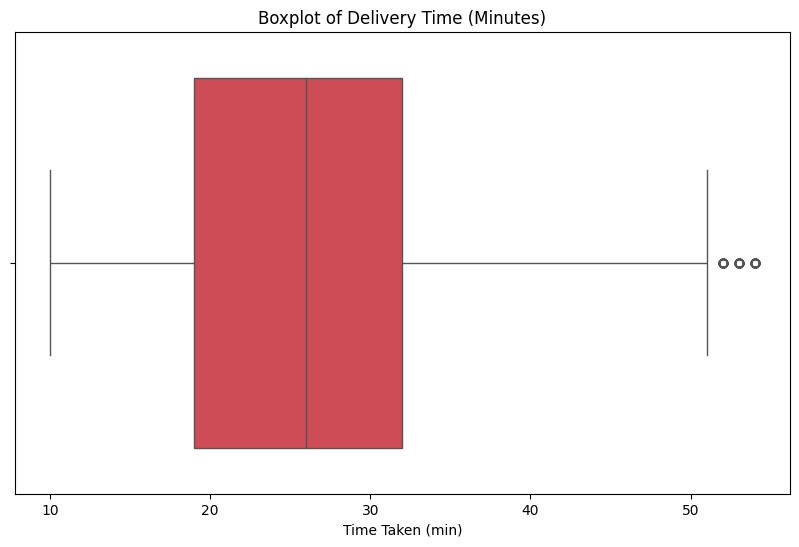

In [35]:
# Boxplot for Delivery Time
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['time_taken_min'],color="#E23744")
plt.title('Boxplot of Delivery Time (Minutes)')
plt.xlabel('Time Taken (min)')
plt.show()

##Customer Experience Enhancement

###Bagaimana variasi rata-rata waktu pengiriman di berbagai kondisi cuaca?

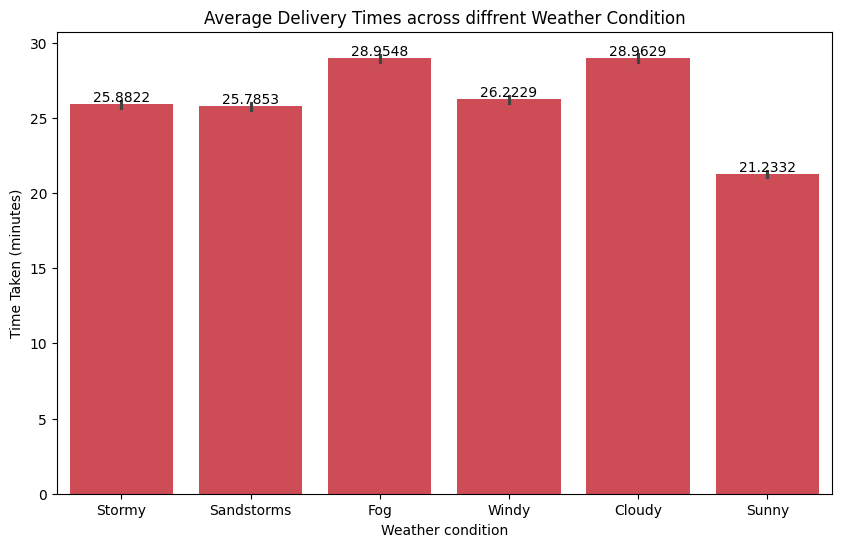

In [36]:
#Bar plot comparing average delivery times across different weather condition.

plt.figure(figsize =(10,6))
ax = sns.barplot(x="weather_conditions", y="time_taken_min", data=df,color="#E23744")

# Add bar labels
for container in ax.containers:
    ax.bar_label(container)

# Show the plot
plt.title("Average Delivery Times across diffrent Weather Condition")
plt.xlabel("Weather condition")
plt.ylabel("Time Taken (minutes)")
plt.show()

####Kesimpulan (Inference):

* Rata-rata waktu pengiriman paling lama terjadi pada kondisi cuaca berawan (cloudy)(28,96 menit) dan berkabut (foggy) (28,95 menit),

* Sementara itu, kondisi cerah (sunny) menghasilkan rata-rata waktu pengiriman tercepat (21,23 menit).

* Badai debu (sandstorms) and cuaca badai (stormy) juga menghasilkan waktu pengiriman yang lebih lama jika dibandingkan dengan kondisi cerah.

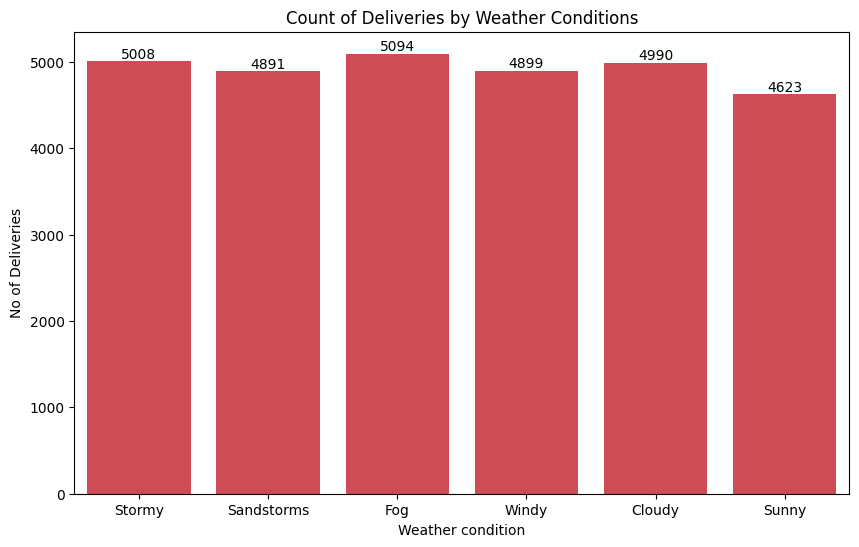

In [37]:
#Bar plot comparing Count of Deliveries by Weather Conditions.

plt.figure(figsize=(10, 6))
ax = sns.countplot(x = "weather_conditions", data=df,color="#E23744")

# Add bar labels
for container in ax.containers:
    ax.bar_label(container)

# Show the plot
plt.title("Count of Deliveries by Weather Conditions")
plt.xlabel("Weather condition")
plt.ylabel("No of Deliveries")
plt.show()

####Kesimpulan (Inference):

* Kabut (fog) memiliki jumlah pesanan tertinggi (5.094),

* Disusul dengan sangat tipis oleh cuaca badai (stormy) (5.008).

* Kondisi cerah (sunny) memiliki volume pesanan terendah (4.623).

###Bagaimana festival musiman memengaruhi waktu pengiriman?

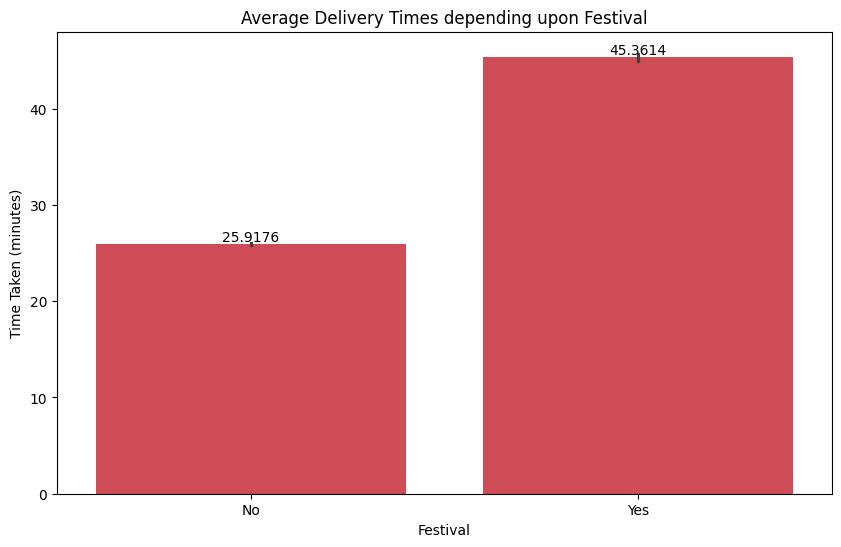

In [38]:
#Bar plot comparing average delivery times depending upon Festival.

plt.figure(figsize =(10,6))
ax = sns.barplot(x="festival", y="time_taken_min", data=df,color="#E23744")

# Add bar labels
for container in ax.containers:
    ax.bar_label(container)

# Show the plot
plt.title("Average Delivery Times depending upon Festival")
plt.xlabel("Festival")
plt.ylabel("Time Taken (minutes)")
plt.show()

####Kesimpulan (Inference):

* Pengiriman selama festival membutuhkan waktu yang jauh lebih lama (45,36 menit) jika dibandingkan dengan waktu di luar festival (25,92 menit), yang menunjukkan bahwa festival berdampak terhadap efisiensi pengiriman.

###Bagaimana pengaruh jenis kendaraan terhadap waktu pengiriman?

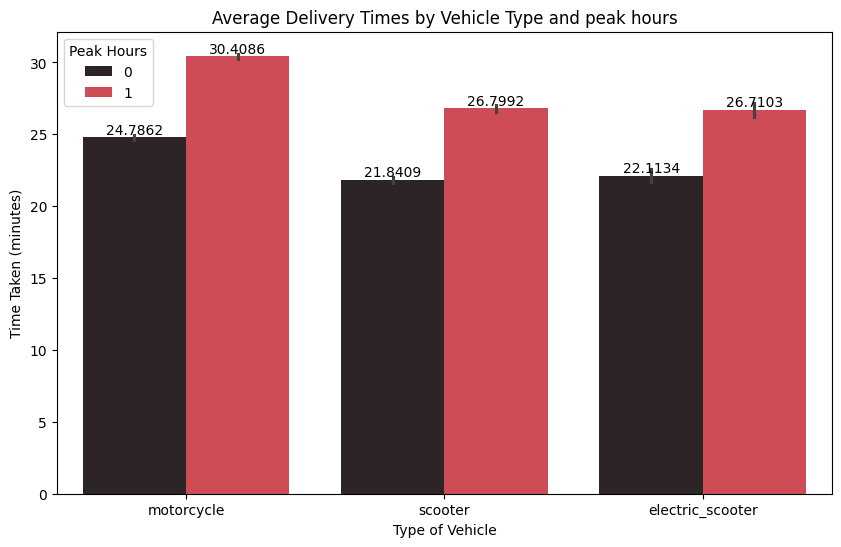

In [39]:
#Bar plot comparing average delivery times across different vehicle types and Peak Hours.

plt.figure(figsize =(10,6))
ax = sns.barplot(x="type_of_vehicle", y="time_taken_min",hue="peak_hours", data=df,color="#E23744")

# Add bar labels
for container in ax.containers:
    ax.bar_label(container)

# Show the plot
plt.title("Average Delivery Times by Vehicle Type and peak hours")
plt.xlabel("Type of Vehicle")
plt.ylabel("Time Taken (minutes)")
plt.legend(title = "Peak Hours")
plt.show()

####Kesimpulan (Inference):

* Waktu pengiriman meningkat selama jam sibuk di semua jenis kendaraan.

* Electric scooters memiliki waktu pengiriman tercepat (22,11 menit) selama jam normal (bukan jam sibuk), tetapi mengalami lonjakan kenaikan yang lebih besar (menjadi 26,71 menit) selama jam sibuk jika dibandingkan dengan motorcycle dan scooter.

###Apakah ada hubungan antara kepadatan lalu lintas jalan dan keterlambatan pengiriman?

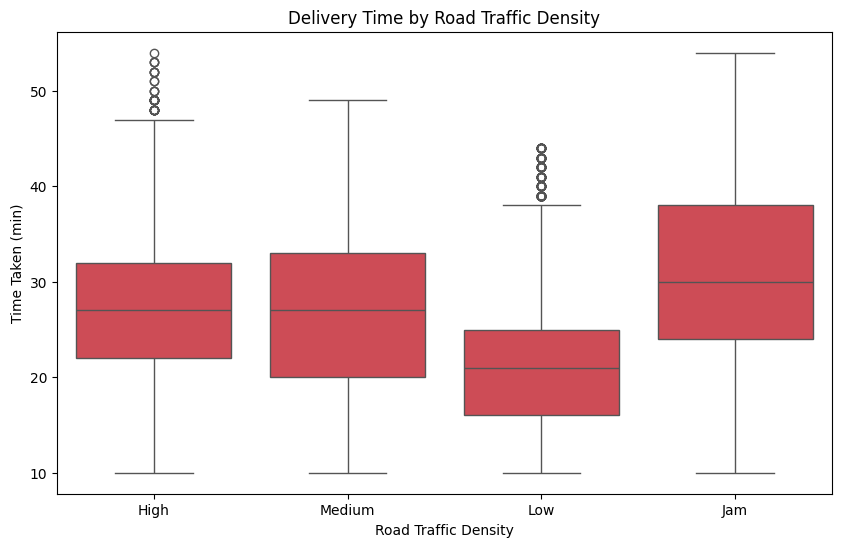

In [40]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='road_traffic_density', y='time_taken_min', data=df,color="#E23744")
plt.title('Delivery Time by Road Traffic Density')
plt.xlabel('Road Traffic Density')
plt.ylabel('Time Taken (min)')
plt.show()

####Kesimpulan (Inference):

* Rata-rata waktu pengiriman tertinggi diamati pada kondisi "Macet/Jam" (31,02 menit), diikuti oleh kondisi "Padat/High" (27,26 menit).

* Kondisi lalu lintas yang lengang (Low) memungkinkan pengiriman tercepat (21,21 menit).

###Bagaimana distribusi waktu pengiriman di berbagai kota?

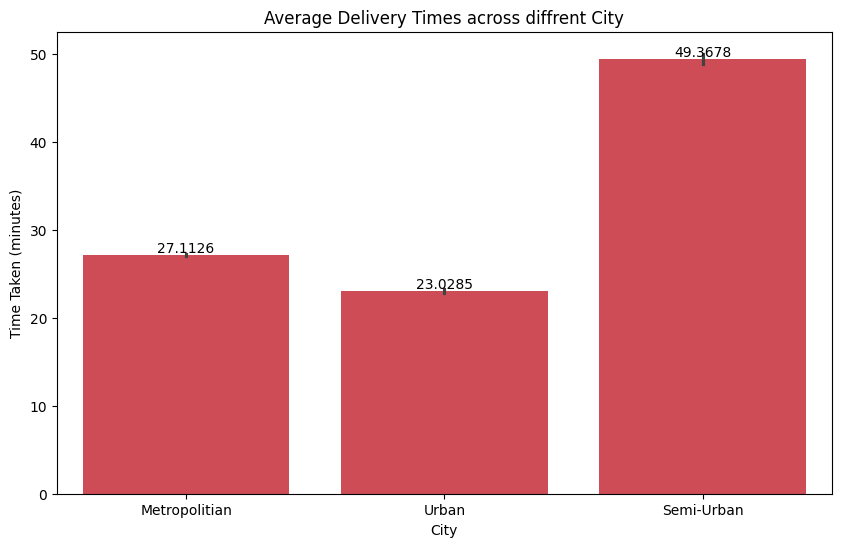

In [41]:
#Bar plot comparing average delivery times across different City.

plt.figure(figsize =(10,6))
ax = sns.barplot(x="city", y="time_taken_min", data=df,color="#E23744")

# Add bar labels
for container in ax.containers:
    ax.bar_label(container)

# Show the plot
plt.title("Average Delivery Times across diffrent City")
plt.xlabel("City")
plt.ylabel("Time Taken (minutes)")
plt.show()

####Kesimpulan (Inference):

* Daerah semi-perkotaan (semi-urban) memiliki rata-rata waktu pengiriman paling lama (49,37 menit),

* Sedangkan daerah perkotaan (urban) memiliki waktu pengiriman paling cepat (23,03 menit).

* Daerah metropolitan berada di kisaran antara keduanya (27,11 menit).

###Bagaimana hubungan antara rata-rata waktu pengiriman dan penilaian (rating) kurir pengantar?

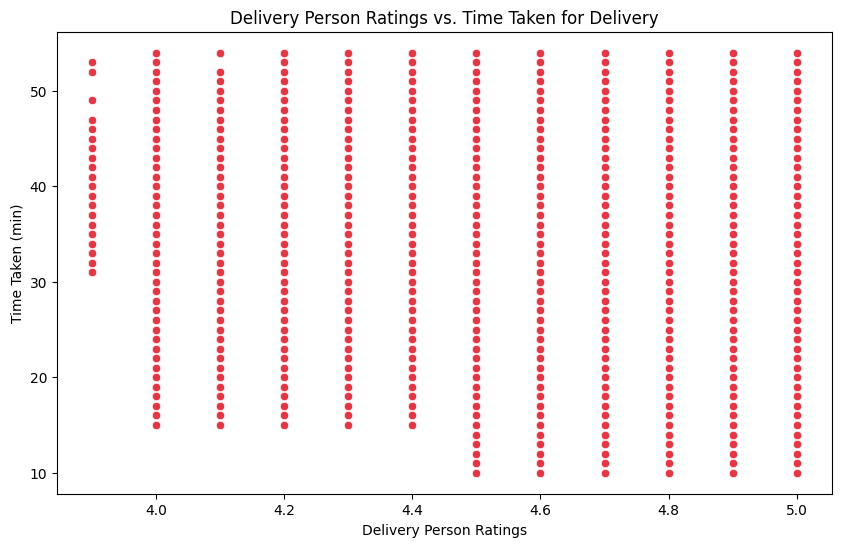

In [42]:
#Scatter plot comparing average delivery times VS Delivery Person Rating.

plt.figure(figsize=(10, 6))
sns.scatterplot(x="delivery_person_ratings", y="time_taken_min", data=df,color="#E23744")
plt.title("Delivery Person Ratings vs. Time Taken for Delivery")
plt.xlabel("Delivery Person Ratings")
plt.ylabel("Time Taken (min)")
plt.show()

####Kesimpulan (Inference):

* Konsentrasi di Rating Tinggi: Sebagian besar data terpusat pada kisaran rating yang tinggi (antara 4,5 hingga 5,0), yang menunjukkan bahwa mayoritas kurir pengantar memiliki penilaian kinerja yang sangat baik.

* Tidak Ada Hubungan Linear yang Kuat: Tidak terlihat adanya korelasi linear atau pola tren yang jelas antara rating kurir dan waktu pengiriman (time taken).

* Variasi Waktu di Setiap Rating: Kurir dengan rating tinggi (misalnya 4,8 atau 5,0) tetap memiliki waktu pengiriman yang sangat bervariasi—mulai dari yang tercepat (sekitar 15 menit) hingga yang paling lambat (mencapai 50 menit lebih). Hal ini mengindikasikan bahwa kecepatan pengiriman lebih dipengaruhi oleh faktor luar seperti kondisi lalu lintas, cuaca, atau jarak, daripada sekadar rating kurir itu sendiri.

###Bagaimana usia kurir pengantar mempengaruhi kinerja pengiriman?

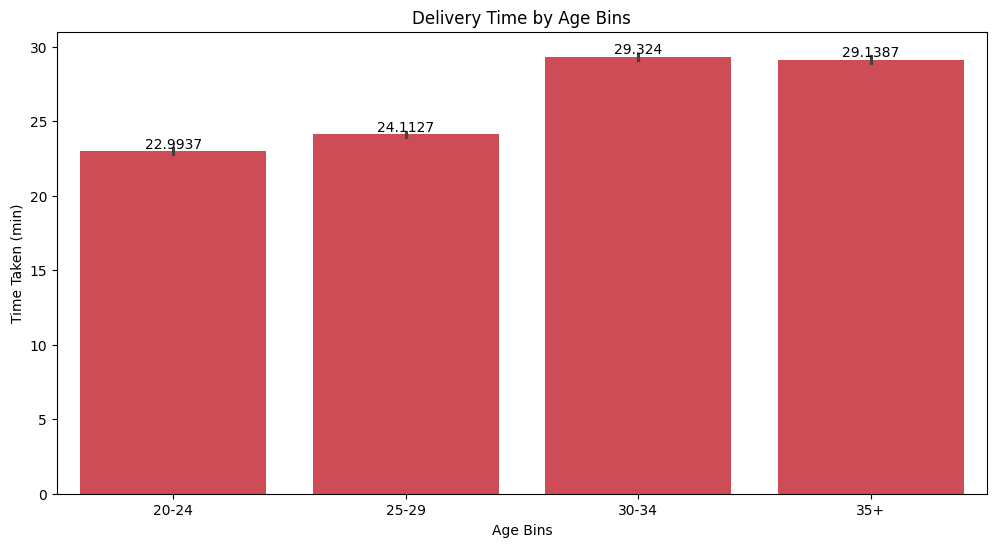

In [43]:
plt.figure(figsize=(12, 6))
ax = sns.barplot(x="age_bins", y="time_taken_min",  data=df,color="#E23744")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Delivery Time by Age Bins")
plt.xlabel("Age Bins")
plt.ylabel("Time Taken (min)")
plt.show()

####Kesimpulan (Inference):

* Rata-rata waktu pengiriman meningkat seiring bertambahnya usia kurir, mencapai puncaknya pada kelompok usia 30-34 tahun (29,32 menit), yang mengindikasikan bahwa kelompok usia kurir ini mungkin mengalami waktu tunggu atau durasi pengiriman yang lebih lama. (Catatan: Konteks "age" di sini merujuk pada usia kurir pengantar, bukan usia pelanggan).

* Sementara itu, kelompok usia kurir 20-24 tahun memiliki waktu pengiriman yang lebih singkat (paling cepat).

###Bagaimana perbedaan rata-rata waktu pengiriman antara jam sibuk (peak hours) dan jam biasa (off-peak hours)?

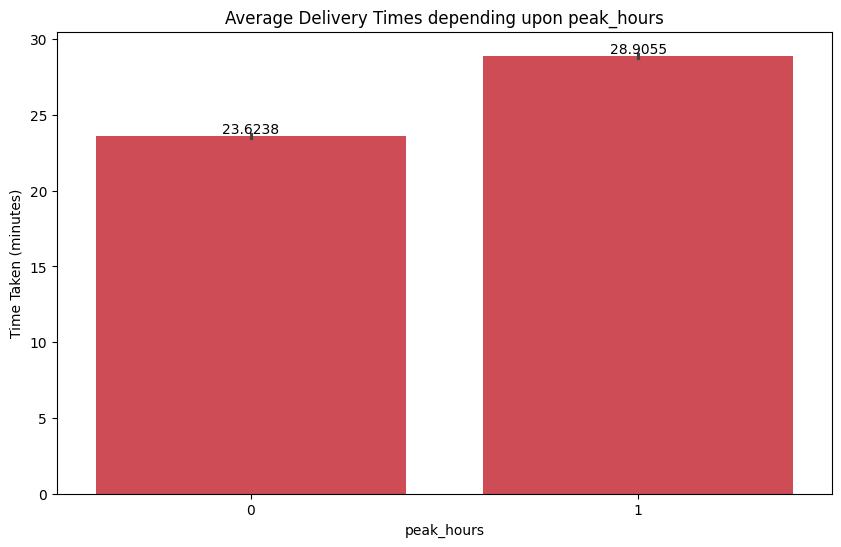

In [44]:
plt.figure(figsize =(10,6))
ax = sns.barplot(x="peak_hours", y="time_taken_min", data=df,color = "#E23744")

# Add bar labels
for container in ax.containers:
    ax.bar_label(container)

# Show the plot
plt.title("Average Delivery Times depending upon peak_hours")
plt.xlabel("peak_hours")
plt.ylabel("Time Taken (minutes)")
plt.show()

####Kesimpulan (Inference):

* Pengiriman selama jam sibuk (peak hours) memiliki rata-rata 28,91 menit, yang secara signifikan lebih lama dibandingkan 23,62 menit pada jam biasa (non-peak hours), yang mengindikasikan bahwa kepadatan lalu lintas mempengaruhi efisiensi pengiriman.

###Apa saja korelasi utama antara berbagai faktor yang memengaruhi operasional pengiriman?

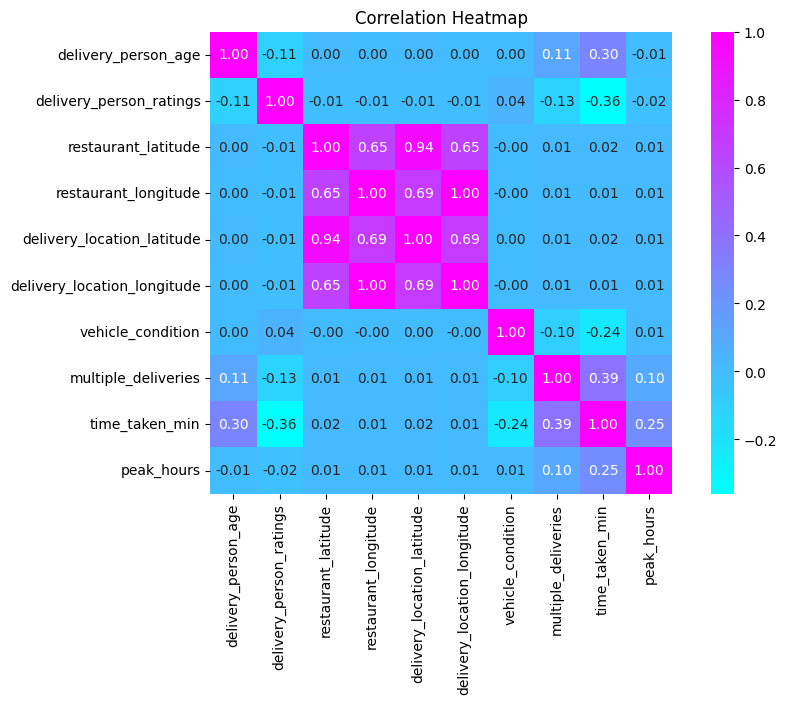

In [45]:
# Using heatmap to view correlation
plt.figure(figsize = (10,6))
sns.heatmap(numeric_columns.corr(), cmap='cool', annot=True, fmt='.2f', square=True)
plt.title('Correlation Heatmap')
plt.show()

####Kesimpulan (Inference):

* Korelasi Antar Fitur Numerik yang Lemah: Berdasarkan heatmap, sebagian besar variabel numerik menunjukkan nilai korelasi yang mendekati nol (atau sangat lemah) satu sama lain.

* Hubungan Spasial Koordinat: Terdapat korelasi positif yang kuat antara koordinat lokasi restoran dan lokasi pengantaran (restaurant_latitude dengan delivery_location_latitude, serta longitude-nya), yang merupakan hal wajar karena titik awal dan akhir pengiriman saling berkaitan secara geografis dalam suatu wilayah.

* Minimnya Korelasi Langsung dengan Waktu Pengiriman: Variabel utama seperti time_taken_min tidak menunjukkan korelasi linear yang kuat secara statistik dengan fitur numerik tunggal lainnya (seperti usia atau kondisi kendaraan), yang mengindikasikan bahwa variasi waktu pengiriman lebih bersifat multivariat—dipengaruhi oleh kombinasi faktor kategori (seperti lalu lintas, cuaca, dan jam sibuk) alih-alih faktor numerik secara terpisah.

##Hypothesis Testing

###Hipotesis 1: Waktu pengiriman lebih cepat untuk kurir pengantar dengan penilaian (rating) yang lebih tinggi.

####Pendekatan:

* Membagi data menjadi dua kelompok: kurir dengan rating tinggi (di atas nilai tengah/median) dan rating rendah (di bawah atau sama dengan median).

* Melakukan uji-t (t-test) untuk membandingkan rata-rata waktu pengiriman.

####Menyiapkan Hipotesis:

* Hipotesis Nol (H0): Tidak ada perbedaan rata-rata waktu pengiriman antara kurir dengan rating tinggi dan rating rendah.

* Hipotesis Alternatif (H1): Kurir dengan rating yang lebih tinggi memiliki rata-rata waktu pengiriman yang lebih cepat.

In [46]:
from scipy.stats import ttest_ind

# Calculate median rating
median_rating = df["delivery_person_ratings"].median()

# Create groups based on ratings
high_rated = df[df["delivery_person_ratings"] > median_rating]["time_taken_min"]
low_rated = df[df["delivery_person_ratings"] <= median_rating]["time_taken_min"]

# Perform t-test
t_stat, p_value = ttest_ind(high_rated, low_rated)

print(f"T-statistic: {t_stat},\nP-value: {p_value}")

# Print Output and Conclusion
alpha = 0.05
if p_value < alpha:
    print("Result: Reject Null Hypothesis")
    print("Conclusion: There is a significant difference in average delivery times between high-rated and low-rated delivery persons. Specifically, higher-rated delivery persons tend to have shorter average delivery times. This suggests that higher ratings may correlate with better performance, possibly due to factors such as experience, efficiency, or customer service skills.")
else:
    print("Result: Fail to Reject Null Hypothesis")
    print("Conclusion: There is no significant difference in average delivery times between high-rated and low-rated delivery persons. This implies that the ratings assigned to delivery personnel may not significantly influence delivery efficiency, suggesting that other factors may play a more critical role in determining delivery times.")

T-statistic: -27.363653241617882,
P-value: 8.042581360076245e-163
Result: Reject Null Hypothesis
Conclusion: There is a significant difference in average delivery times between high-rated and low-rated delivery persons. Specifically, higher-rated delivery persons tend to have shorter average delivery times. This suggests that higher ratings may correlate with better performance, possibly due to factors such as experience, efficiency, or customer service skills.


####Kesimpulan (Inference):

* Kurir dengan peringkat yang lebih tinggi memiliki rata-rata waktu pengiriman yang lebih singkat, yang menunjukkan bahwa pengalaman atau keterampilan dapat memengaruhi kinerja.

####Rekomendasi:

* Menerapkan sistem pelacakan kinerja yang memberikan insentif untuk peringkat yang tinggi melalui program penghargaan atau pengakuan. Selain itu, berikan pelatihan bagi kurir dengan peringkat yang lebih rendah guna meningkatkan keterampilan dan efisiensi kerja mereka.

###Hipotesis 2: Waktu pengiriman berbeda berdasarkan kondisi cuaca.

####Pendekatan:

* Ini adalah perbandingan antara variabel kategori dan variabel numerik, di mana variabel kategori memiliki lebih dari dua kategori.

* Gunakan ANOVA untuk membandingkan waktu pengiriman di berbagai kategori cuaca.

####Penyusunan Hipotesis:

* Hipotesis Nol (H0): Tidak ada perbedaan rata-rata waktu pengiriman di berbagai kondisi cuaca.

* Hipotesis Alternatif (H1): Rata-rata waktu pengiriman berbeda berdasarkan kondisi cuaca.

In [47]:
from scipy.stats import f_oneway

# Calculate time taken for each weather condition as lists of values

Cloudy     = df[df["weather_conditions"]=="Cloudy"]["time_taken_min"]
Fog        = df[df["weather_conditions"]=="Fog"]["time_taken_min"]
Sandstorms = df[df["weather_conditions"]=="Sandstorms"]["time_taken_min"]
Stormy     = df[df["weather_conditions"]=="Stormy"]["time_taken_min"]
Sunny      = df[df["weather_conditions"]=="Sunny"]["time_taken_min"]
Windy      = df[df["weather_conditions"]=="Windy"]["time_taken_min"]

# Perform ANOVA
f_stat, p_value = f_oneway(Cloudy,Fog,Sandstorms,Stormy,Sunny,Windy)
print(f"T-statistic: {f_stat},\nP-value: {p_value}")

# Print Output and Conclusion
alpha = 0.05
if p_value < alpha:
    print("Result: Reject Null Hypothesis")
    print("Conclusion: There is a significant difference in average delivery times based on weather conditions. This suggests that various weather conditions impact delivery efficiency, indicating that some conditions may lead to longer delivery times than others.")
else:
    print("Result: Fail to Reject Null Hypothesis")
    print("Conclusion: There is no significant difference in average delivery times across different weather conditions. This implies that weather may not be a critical factor influencing delivery times, suggesting that other variables might play a more significant role in affecting delivery efficiency.")

T-statistic: 503.0504065592345,
P-value: 0.0
Result: Reject Null Hypothesis
Conclusion: There is a significant difference in average delivery times based on weather conditions. This suggests that various weather conditions impact delivery efficiency, indicating that some conditions may lead to longer delivery times than others.


####Kesimpulan (Inference):

* Cuaca sangat memengaruhi efisiensi pengiriman, di mana kondisi tertentu menyebabkan waktu pengiriman menjadi lebih lama.

####Rekomendasi:

* Buatlah rencana pengiriman yang dapat disesuaikan berdasarkan kondisi cuaca. Hal ini dapat mencakup pembaruan perkiraan waktu pengiriman saat cuaca buruk dan penyediaan perlengkapan yang tepat bagi para pekerja pengantar barang, seperti jas hujan, agar tetap efisien.

###Hipotesis 3: Kurir yang lebih tua memiliki waktu pengiriman yang lebih lama.

####Pendekatan:

* Ini adalah perbandingan antara variabel kategori (kelompok usia) dan variabel numerik (waktu pengiriman). Gunakan uji-t dua sampel (two-sample t-test).

* Buat kelompok usia (misalnya, lebih muda dari 30 tahun dan 30 tahun ke atas) dan lakukan uji-t untuk membandingkan rata-rata waktu pengiriman antara kelompok-kelompok ini.

####Penyusunan Hipotesis:

* Hipotesis Nol (H0): Tidak ada perbedaan rata-rata waktu pengiriman antara kurir muda (lebih muda dari 30 tahun) dan kurir tua (30 tahun atau lebih).

* Hipotesis Alternatif (H1): Terdapat perbedaan yang signifikan dalam rata-rata waktu pengiriman antara kurir muda dan kurir tua.

In [48]:
# Define age groups
df["Age_Group"] = ["Younger" if age <= 30 else "Older" for age in df["delivery_person_age"]]

# Group by age group
younger_deliveries = df[df["Age_Group"] == "Younger"]["time_taken_min"]
older_deliveries = df[df["Age_Group"] == "Older"]["time_taken_min"]

# Perform t-test
t_stat, p_value = ttest_ind(younger_deliveries, older_deliveries)
print(f"T-statistic: {t_stat},\nP-value: {p_value}")

# Print Output and Conclusion
alpha = 0.05
if p_value < alpha:
    print("Result: Reject Null Hypothesis")
    print("Conclusion: There is a significant difference in average delivery times between young and old delivery persons. This suggests that age may impact delivery performance.")
else:
    print("Result: Fail to Reject Null Hypothesis")
    print("Conclusion: There is no significant difference in average delivery times between young and old delivery persons. This suggests that age does not have a notable effect on delivery performance.")

T-statistic: -56.38644179760498,
P-value: 0.0
Result: Reject Null Hypothesis
Conclusion: There is a significant difference in average delivery times between young and old delivery persons. This suggests that age may impact delivery performance.


####Kesimpulan (Inference):

* Terdapat perbedaan yang signifikan dalam rata-rata waktu pengiriman antara kurir muda dan kurir tua. Pertimbangkan untuk menyesuaikan program pelatihan guna memenuhi kebutuhan khusus dari berbagai kelompok usia.

####Rekomendasi:
* Promosikan program mentoring (bimbingan) antara pekerja pengantar barang yang lebih muda dan yang lebih tua guna membantu berbagi pengetahuan dan meningkatkan keterampilan.

###Hipotesis 4: Waktu pengiriman sangat dipengaruhi oleh kepadatan lalu lintas jalan.

####Pendekatan:

* Ini adalah perbandingan antara variabel kategori (tingkat kepadatan lalu lintas jalan) dan variabel numerik (waktu pengiriman).

* Gunakan ANOVA untuk menilai perbedaan rata-rata waktu pengiriman di antara berbagai kategori kepadatan lalu lintas.

####Penyusunan Hipotesis:

* Hipotesis Nol (H0): Tidak ada perbedaan rata-rata waktu pengiriman di berbagai tingkat kepadatan lalu lintas jalan.

* Hipotesis Alternatif (H1): Terdapat perbedaan yang signifikan dalam rata-rata waktu pengiriman di berbagai tingkat kepadatan lalu lintas jalan.

In [49]:
from scipy.stats import f_oneway

# Calculate time taken for each weather condition as lists of values

Low    = df[df["road_traffic_density"]=="Low"]["time_taken_min"]
Jam    = df[df["road_traffic_density"]=="Jam"]["time_taken_min"]
Medium = df[df["road_traffic_density"]=="Medium"]["time_taken_min"]
High   = df[df["road_traffic_density"]=="High"]["time_taken_min"]


# Perform ANOVA
f_stat, p_value = f_oneway(Low,Jam,Medium,High)
print(f"T-statistic: {f_stat},\nP-value: {p_value}")

# Print Output and Conclusion
alpha = 0.05
if p_value < alpha:
    print("Result: Reject Null Hypothesis")
    print("Conclusion: There is a significant difference in average delivery times across different levels of road traffic density. This indicates that traffic conditions play a crucial role in determining delivery efficiency, with varying densities affecting how quickly deliveries are completed.")
else:
    print("Result: Fail to Reject Null Hypothesis")
    print("Conclusion: There is no significant difference in average delivery times across different levels of road traffic density. This suggests that road traffic density may not be a key factor influencing delivery times, indicating that other variables could be more impactful.")

T-statistic: 2339.561846454143,
P-value: 0.0
Result: Reject Null Hypothesis
Conclusion: There is a significant difference in average delivery times across different levels of road traffic density. This indicates that traffic conditions play a crucial role in determining delivery efficiency, with varying densities affecting how quickly deliveries are completed.


####Kesimpulan (Inference):

* Kondisi lalu lintas sangat memengaruhi waktu pengiriman, di mana tingkat kepadatan yang berbeda-beda berdampak pada kecepatan.

####Rekomendasi:

* Manfaatkan data dan analitik lalu lintas secara real-time (langsung) untuk mengoptimalkan rute pengiriman. Berinvestasilah pada teknologi yang memungkinkan pengalihan rute dinamis (dynamic rerouting) berdasarkan kondisi lalu lintas saat ini guna meminimalkan keterlambatan.

###Hipotesis 5: Waktu pengiriman lebih lama selama hari libur/festival.

####Pendekatan:

* Ini adalah perbandingan antara variabel kategori (terjadinya festival) dan variabel numerik (waktu pengiriman).

* Gunakan uji-t (t-test) untuk menilai perbedaan rata-rata waktu pengiriman antara pengiriman yang dilakukan selama festival dan yang dilakukan di luar periode festival.

####Penyusunan Hipotesis:

* Hipotesis Nol (H0): Tidak ada perbedaan rata-rata waktu pengiriman antara pengiriman yang dilakukan selama hari libur/festival dan yang dilakukan di luar periode festival.

* Hipotesis Alternatif (H1): Rata-rata waktu pengiriman secara signifikan lebih lama untuk pengiriman yang dilakukan selama hari libur/festival dibandingkan dengan pengiriman di luar periode festival.

In [50]:
festival_deliveries = df[df["festival"] == "Yes"]["time_taken_min"]
non_festival_deliveries = df[df["festival"] == "No"]["time_taken_min"]

# Perform t-test
t_stat, p_value = ttest_ind(festival_deliveries, non_festival_deliveries)

print(f"T-statistic: {t_stat},\nP-value: {p_value}")
# Print Output and Conclusion
alpha = 0.05
if p_value < alpha:
    print("Result: Reject Null Hypothesis")
    print("Conclusion: This suggests that delivery times are indeed significantly longer during festival periods, potentially due to increased traffic, higher demand, or other contributing factors.")
else:
    print("Result: Fail to Reject Null Hypothesis")
    print("Conclusion: This implies that there is no significant difference in delivery times during festivals compared to non-festival periods, indicating that festivals may not substantially impact delivery efficiency")

T-statistic: 49.158734358977945,
P-value: 0.0
Result: Reject Null Hypothesis
Conclusion: This suggests that delivery times are indeed significantly longer during festival periods, potentially due to increased traffic, higher demand, or other contributing factors.


####Kesimpulan (Inference):

* Waktu pengiriman secara signifikan lebih lama selama periode festival, yang kemungkinan besar disebabkan oleh peningkatan lalu lintas dan lonjakan permintaan.

####Rekomendasi:
* Bersiaplah menghadapi tingginya permintaan selama festival dengan menambah jumlah staf dan sumber daya pengiriman. Sediakan opsi prapesanan (pre-order) atau atur slot waktu untuk mengelola ekspektasi pelanggan dan meningkatkan layanan selama periode tersebut.

###Hipotesis 6: Jenis kendaraan yang berbeda memiliki rata-rata waktu pengiriman yang berbeda.

####Pendekatan:

* Ini adalah perbandingan antara variabel kategori (jenis kendaraan) dan variabel numerik (waktu pengiriman).

* Gunakan ANOVA (Analisis Varian) untuk menilai perbedaan rata-rata waktu pengiriman di antara berbagai jenis kendaraan.

####Penyusunan Hipotesis:

* Hipotesis Nol (H0): Tidak ada perbedaan rata-rata waktu pengiriman di antara berbagai jenis kendaraan.

* Hipotesis Alternatif (H1): Terdapat perbedaan yang signifikan dalam rata-rata waktu pengiriman di antara berbagai jenis kendaraan.

In [51]:
# Calculate time taken for each vehicle type

motorcycle       = df[df["type_of_vehicle"]=="motorcycle"]["time_taken_min"]
scooter          = df[df["type_of_vehicle"]=="scooter"]["time_taken_min"]
electric_scooter = df[df["type_of_vehicle"]=="electric_scooter"]["time_taken_min"]


# Perform ANOVA
f_stat, p_value = f_oneway(motorcycle,scooter,electric_scooter)
print(f"T-statistic: {f_stat},\nP-value: {p_value}")

# Print Output and Conclusion
alpha = 0.05
if p_value < alpha:
    print("Result: Reject Null Hypothesis")
    print("Conclusion: There is a significant difference in average delivery times among different types of vehicles.")
else:
    print("Result: Fail to Reject Null Hypothesis")
    print("Conclusion: There is no difference in average delivery times among different types of vehicles.")

T-statistic: 450.84522351181033,
P-value: 1.3582632679622862e-193
Result: Reject Null Hypothesis
Conclusion: There is a significant difference in average delivery times among different types of vehicles.


####Kesimpulan (Inference):

* Rata-rata waktu pengiriman bervariasi secara signifikan berdasarkan jenis kendaraan, yang menunjukkan bahwa beberapa kendaraan lebih efisien untuk pengiriman.

####Rekomendasi:
* Analisis jenis kendaraan apa yang menghasilkan waktu pengiriman tercepat dan sesuaikan komposisi armada kendaraan yang dimiliki. Dorong penggunaan kendaraan yang lebih cepat selama jam-jam sibuk pengiriman atau di area yang padat.

###Hipotesis 7: Waktu pengiriman bervariasi secara signifikan berdasarkan kota.

####Pendekatan:

* Mirip dengan analisis kendaraan, hipotesis ini membandingkan variabel kategori (kota) dengan variabel numerik (waktu pengiriman).

* Sekali lagi, ANOVA adalah metode yang tepat untuk digunakan di sini.

####Penyusunan Hipotesis:

* Hipotesis Nol (H0): Tidak ada perbedaan rata-rata waktu pengiriman di antara berbagai kota.

* Hipotesis Alternatif (H1): Terdapat perbedaan yang signifikan dalam rata-rata waktu pengiriman di antara berbagai kota.

In [52]:
# Calculate time taken for each City type

Metropolitian  = df[df["city"]=="Metropolitian"]["time_taken_min"]
Urban          = df[df["city"]=="Urban"]["time_taken_min"]
Semi_Urban     = df[df["city"]=="Semi-Urban"]["time_taken_min"]


# Perform ANOVA
f_stat, p_value = f_oneway(Metropolitian,Urban,Semi_Urban)
print(f"T-statistic: {f_stat},\nP-value: {p_value}")

# Print Output and Conclusion
alpha = 0.05
if p_value < alpha:
    print("Result: Reject Null Hypothesis")
    print("Conclusion: There is a significant difference in average delivery times among different cities.")
else:
    print("Result: Fail to Reject Null Hypothesis")
    print("Conclusion: There is no difference in average delivery times among different cities.")

T-statistic: 850.4819711162505,
P-value: 0.0
Result: Reject Null Hypothesis
Conclusion: There is a significant difference in average delivery times among different cities.


####Kesimpulan (Inference):

* Analisis mengungkapkan bahwa rata-rata waktu pengiriman bervariasi secara signifikan di berbagai kota, yang menunjukkan bahwa faktor-faktor seperti kondisi lalu lintas, infrastruktur, dan regulasi lokal dapat memengaruhi efisiensi pengiriman.

####Rekomendasi:
* Lakukan analisis mendalam untuk mengidentifikasi faktor spesifik yang berkontribusi terhadap perbedaan waktu pengiriman di setiap kota. Gunakan informasi ini untuk menyesuaikan strategi pengiriman di setiap lokasi, seperti mengoptimalkan rute, menyesuaikan tingkat kepegawaian, atau menerapkan solusi logistik khusus per kota guna meningkatkan kinerja pengiriman secara keseluruhan.

###Hipotesis 8: Waktu pengiriman lebih lama selama jam-jam sibuk (peak hours).

####Pendekatan:

* Hipotesis ini membandingkan variabel kategori (jam sibuk: ya/tidak) dengan variabel numerik (waktu pengiriman).

* Gunakan uji-t (t-test) untuk menilai perbedaan rata-rata waktu pengiriman antara jam sibuk dan jam tidak sibuk.

####Penyusunan Hipotesis:

* Hipotesis Nol (H0): Tidak ada perbedaan rata-rata waktu pengiriman antara jam sibuk dan jam tidak sibuk.

* Hipotesis Alternatif (H1): Rata-rata waktu pengiriman secara signifikan lebih lama selama jam sibuk dibandingkan dengan jam tidak sibuk.

In [53]:
# Split data into peak and non-peak hours
peak_deliveries = df[df["peak_hours"] == 1]["time_taken_min"]
non_peak_deliveries = df[df["peak_hours"] == 0]["time_taken_min"]

# Perform t-test
t_stat_peak, p_value_peak = ttest_ind(peak_deliveries, non_peak_deliveries)
print(f"Peak Hours T-statistic: {t_stat_peak},\nP-value: {p_value_peak}")

# Print Output and Conclusion
alpha = 0.05
if p_value_peak < alpha:
    print("Result: Reject Null Hypothesis")
    print("Conclusion: Average delivery times are significantly longer during peak hours compared to non-peak hours.")
else:
    print("Result: Fail to Reject Null Hypothesis")
    print("Conclusion: There is no difference in average delivery times between peak hours and non-peak hours.")

Peak Hours T-statistic: 52.06823198878402,
P-value: 0.0
Result: Reject Null Hypothesis
Conclusion: Average delivery times are significantly longer during peak hours compared to non-peak hours.


####Kesimpulan (Inference):

* Pengiriman memakan waktu lebih lama selama jam-jam sibuk (peak hours), yang menunjukkan peningkatan kemacetan dan permintaan.

####Rekomendasi:
* Pertimbangkan untuk menerapkan harga lonjakan (surge pricing) selama jam sibuk guna menyeimbangkan permintaan dan pasokan. Dorong pelanggan untuk memilih opsi pengiriman di luar jam sibuk (off-peak) melalui insentif atau diskon.

###Hipotesis 9: Terdapat efek interaksi antara jam sibuk (peak hours) dan jenis pesanan (type of order) terhadap waktu pengiriman.

####Pendekatan:

* Hipotesis ini menguji interaksi antara dua variabel kategori (jam sibuk dan jenis pesanan) terhadap variabel numerik (waktu pengiriman).

* Gunakan ANOVA dua arah (two-way ANOVA) untuk menilai efek interaksi tersebut.

####Penyusunan Hipotesis:

* Hipotesis Nol (H0): Tidak ada efek interaksi antara jam sibuk dan jenis pesanan terhadap rata-rata waktu pengiriman.

* Hipotesis Alternatif (H1): Terdapat efek interaksi antara jam sibuk dan jenis pesanan terhadap rata-rata waktu pengiriman.

In [54]:
import pandas as pd
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Assume 'data' is your DataFrame

# Hypothesis 1: Peak Hours
peak_hours_delivery_times = df[df["peak_hours"] == 1]["time_taken_min"]
non_peak_hours_delivery_times = df[df["peak_hours"] == 0]["time_taken_min"]

t_statistic, p_value_peak = stats.ttest_ind(peak_hours_delivery_times, non_peak_hours_delivery_times, equal_var=True)

print(f"Peak Hours T-Test: T-statistic = {t_statistic},\nPvalue = {p_value_peak}")

# Hypothesis 2: Type of Orders
model_orders = ols("time_taken_min ~ C(type_of_order)",data=df).fit()
anova_orders = sm.stats.anova_lm(model_orders, typ=2)

print("\nANOVA results for Type of Orders:")
print(anova_orders)

# Hypothesis 3: Interaction Effect
model_interaction = ols("time_taken_min ~ C(peak_hours) * C(type_of_order)", data=df).fit()
anova_interaction = sm.stats.anova_lm(model_interaction, typ=2)

print("\nANOVA results for Interaction Effect:")
print(anova_interaction)
print()

# Output and Conclusion for Hypothesis 2
anova_orders_p_value = anova_orders["PR(>F)"][0]

if anova_orders_p_value < alpha:
    print("Result: Reject Null Hypothesis")
    print("Conclusion: There is a significant difference in average delivery times among different types of orders.\n")
else:
    print("Result: Fail to Reject Null Hypothesis")
    print("Conclusion: There is no difference in average delivery times among different types of orders.\n")

# Output and Conclusion for Hypothesis 3

anova_interaction_p_value = anova_interaction["PR(>F)"]["C(peak_hours):C(type_of_order)"]  # Extract interaction p-value

if anova_interaction_p_value < alpha:
    print("Result: Reject Null Hypothesis")
    print("Conclusion: There is a significant interaction effect between peak hours and type of order on delivery times.")
else:
    print("Result: Fail to Reject Null Hypothesis")
    print("Conclusion: There is no significant interaction effect between peak hours and type of order on delivery times.")

Peak Hours T-Test: T-statistic = 52.06823198878402,
Pvalue = 0.0

ANOVA results for Type of Orders:
                        sum_sq       df       F    PR(>F)
C(type_of_order)  6.855342e+02      3.0  2.7581  0.040689
Residual          2.444188e+06  29501.0     NaN       NaN

ANOVA results for Interaction Effect:
                                      sum_sq       df            F    PR(>F)
C(peak_hours)                   2.056271e+05      1.0  2709.509996  0.000000
C(type_of_order)                5.549243e+02      3.0     2.437379  0.062609
C(peak_hours):C(type_of_order)  7.977815e+00      3.0     0.035041  0.991216
Residual                        2.238553e+06  29497.0          NaN       NaN

Result: Reject Null Hypothesis
Conclusion: There is a significant difference in average delivery times among different types of orders.

Result: Fail to Reject Null Hypothesis
Conclusion: There is no significant interaction effect between peak hours and type of order on delivery times.


####Kesimpulan (Inference):

* Tidak ada efek interaksi yang signifikan antara jam sibuk (peak hours) dan jenis pesanan terhadap waktu pengiriman, yang menunjukkan bahwa jam sibuk memengaruhi semua jenis pesanan dengan cara yang serupa.

####Rekomendasi:

* Fokuslah pada strategi umum untuk mengurangi waktu pengiriman selama jam sibuk, daripada menerapkan strategi khusus berdasarkan jenis pesanan. Hal ini mencakup pengoptimalan jumlah staf dan logistik guna meningkatkan kinerja secara keseluruhan selama jam-jam sibuk tersebut.

##Rekomendasi

###Mengoptimalkan Strategi Pengiriman untuk Kondisi Cuaca:

* Terapkan strategi untuk mengurangi keterlambatan selama cuaca buruk, seperti menggunakan lebih banyak personel pengiriman atau menyesuaikan waktu pengiriman berdasarkan prakiraan cuaca.

* Peningkatan komunikasi dengan pelanggan selama kondisi ini dapat meningkatkan kepuasan.

###Menyesuaikan Operasional Selama Hari Libur/Festival:

* Pertimbangkan untuk menambah jumlah personel pengiriman atau memberikan insentif untuk pengiriman selama periode festival guna mengatasi peningkatan waktu pengiriman.

###Memanfaatkan Jenis Kendaraan secara Efisien:

* Prioritaskan penggunaan skuter listrik selama jam tidak sibuk untuk pengiriman yang lebih cepat.

* Latih para pengemudi untuk mengoptimalkan rute selama jam sibuk guna meminimalkan keterlambatan.

###Manajemen Lalu Lintas:

* Bekerja sama dengan pihak berwenang lalu lintas setempat untuk menerima pembaruan lalu lintas secara real-time.

* Terapkan teknologi pengoptimalan rute untuk mengurangi waktu pengiriman, terutama dalam kondisi lalu lintas padat dan macet.

###Pemasaran yang Ditargetkan untuk Berbagai Jenis Kota:

* Kembangkan strategi pemasaran yang ditargetkan untuk area semi-perkotaan guna meningkatkan volume pesanan.

* Pertimbangkan promosi atau program loyalitas untuk mendorong lebih banyak pesanan pada saat permintaan sedang lesu.

###Strategi Jam Sibuk (Peak Hour):

* Perkenalkan harga yang lebih tinggi selama jam sibuk untuk mengendalikan permintaan dan mendorong pengiriman pada waktu yang lebih sepi.

* Tingkatkan jumlah staf selama jam-jam tersebut untuk menjaga kualitas layanan tetap tinggi.

##Ringkasan

* Dengan mengatasi berbagai temuan ini melalui rekomendasi strategis, layanan pengiriman dapat meningkatkan efisiensi, memperbaiki kepuasan pelanggan, serta beradaptasi lebih baik terhadap berbagai kondisi dan tantangan.

* Penerapan rekomendasi ini akan membantu merampingkan operasional dan menciptakan sistem pengiriman yang lebih responsif.

In [61]:
output_filename = "zomato_cleaned_data.csv"
df.to_csv(output_filename, index=False)

from google.colab import files
files.download(output_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>